In [1]:
print("Hello Conor")

Hello Conor


In [38]:
#need to import packages

try:
    import pyarrow
except ModuleNotFoundError:
    ! pip install pyarrow
    import pyarrow



import numpy as np
import pandas as pd
from urllib.request import urlopen
from pathlib import Path
import gzip


In [39]:
#Now we read in the files, set it up to be reproducible and changing paths is easy
city = 'London'
ymd = '20260917'
host = 'https://orca.casa.ucl.ac.uk'
url = f'{host}/~jreades/data/{ymd}-{city}-listings.csv.gz'

#reproducible path read in

if Path.cwd().name == 'data_prep':
    dir_data = Path('../data')
else:
    dir_data = Path('data')
dir_raw = dir_data / 'raw'
dir_clean = dir_data / 'clean'

print(f'Data folder is: {dir_data}')
print(f'Raw data folder is: {dir_raw}')
print(f'Clean data folder is: {dir_clean}')

#since we are using multiple years each year needs a folder
#use the same file name as the url so it matches the qmd and doesn't download twice
path = dir_raw / ymd[:4] / Path(url).name
print(f'Writing out data to: {path}')


Data folder is: ..\data
Raw data folder is: ..\data\raw
Clean data folder is: ..\data\clean
Writing out data to: ..\data\raw\2026\20260917-London-listings.csv.gz


In [40]:
#next we need to select the columns we need from our datasets

cols = ['id', 'listing_url', 'last_scraped', 'name',
    'description', 'host_id', 'host_name', 'host_since',
    'host_location', 'host_about', 'host_is_superhost',
    'host_listings_count', 'host_total_listings_count',
    'host_verifications', 'latitude', 'longitude',
    'property_type', 'room_type', 'accommodates',
    'bathrooms', 'bathrooms_text', 'bedrooms', 'beds',
    'amenities', 'price', 'minimum_nights', 'maximum_nights',
    'availability_365', 'number_of_reviews',
    'first_review', 'last_review', 'review_scores_rating',
    'license', 'reviews_per_month']

#extra columns that might be interesting for answering the qs
extra_cols = ['neighbourhood_cleansed',
    'number_of_reviews_ltm', 'calculated_host_listings_count',
    'calculated_host_listings_count_entire_homes', 'estimated_occupancy_l365d',
    'estimated_revenue_l365d']

cols = cols + extra_cols

print (len(cols))




40


In [41]:

#now we need to download the data and read it in.

def test_gzip(file_path):
    """Test if a file is a valid gzip file."""
    try:
        with gzip.open(file_path, 'rb') as f:
            f.read(1024 * 1024)
        return True
    except (OSError, EOFError):
        return False

def download_and_read_csvs(url, path):
    if not path.exists() or not test_gzip(path):
        if path.exists():
            path.unlink()  #remove file if it does exist but is not a valid gzip file
        print(f'Downloading data from {url}...')
        path.parent.mkdir(parents=True, exist_ok=True)  #make sure the directory exists
        with urlopen(url) as response, open(path, 'wb') as out_file:
            while chunk := response.read(1024 * 1024):
                out_file.write(chunk)

download_and_read_csvs(url, path)

df = pd.read_csv(path, compression = 'gzip', low_memory = False, usecols = cols, dtype = {'id' : str, 'host_id' : str})

print(f' dataframe is {df.shape[0]} rows by {df.shape[1]} columns')


 dataframe is 91954 rows by 40 columns


Our dataframe now has 91954 rows, 40 columns
host_since                   91954
bathrooms                    91954
host_total_listings_count    91954
host_verifications           91954
license                      91954
host_about                   42695
price                        32049
estimated_revenue_l365d      32049
host_location                22885
last_review                  20694
review_scores_rating         20694
reviews_per_month            20694
dtype: int64
These columns are empty: Index(['host_since', 'host_total_listings_count', 'host_verifications',
       'bathrooms', 'license'],
      dtype='str')
Our dataframe now has 91954 rows, 34 columns
0    33927
1    32882
2     4105
3      191
4     7157
5    11391
6     2187
7      110
8        4
Name: count, dtype: int64
Dropping 2301 rows with more than 5 missing values
Our dataframe now has 89653 rows, 34 columns
Dropped rows with any reviews: 0


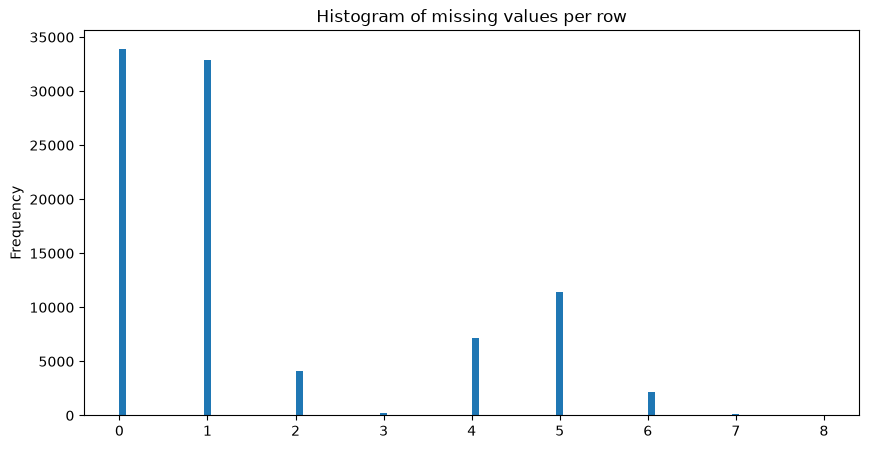

In [42]:
#now we need to drop rows that have no id.

df = df.dropna(subset=['id'])
print(f'Our dataframe now has {df.shape[0]} rows, {df.shape[1]} columns')

#now we check the columns
print(df.isnull().sum().sort_values(ascending = False)[:12])

empty_cols = df.columns[df.isnull().all().to_list()]
print(f'These columns are empty: {empty_cols}')
#also drop host_about, it's missing for about half the listings and would push normal rows over the cutoff
df = df.drop(columns=list(empty_cols) + ['host_about'])
print(f'Our dataframe now has {df.shape[0]} rows, {df.shape[1]} columns')

#count missing values per row over the practical's columns only (not extra_cols)
probability = df.drop(columns=extra_cols).isnull().sum(axis = 1)

probability.plot.hist(bins = 100, figsize = (10, 5), title = 'Histogram of missing values per row')
print(probability.value_counts().sort_index())

#now we get rid of the rows that have more than 5 missing values from the practical.
cutoff = 5
dropped = df[probability > cutoff]
print(f'Dropping {(probability > cutoff).sum()} rows with more than {cutoff} missing values')

df = df[probability <= cutoff]
print(f'Our dataframe now has {df.shape[0]} rows, {df.shape[1]} columns')

print(f"Dropped rows with any reviews: {(dropped.number_of_reviews > 0).sum()}")


In [26]:
#we need to ensure that the types are correct for our columns.
#used chatgpt here to help debug code where I needed to add filters in first.

#boolieans
bool_cols = ['host_is_superhost']
for b in bool_cols:
    df[b] = df[b].replace({'t': True, 'f': False}).astype(bool)

#dates
dates = [d for d in ['last_scraped', 'host_since', 'first_review', 'last_review'] if d in df.columns]
for d in dates:
    df[d] = pd.to_datetime(df[d], errors='coerce')

#categories, plus the boroughs
cats = ['neighbourhood_cleansed', 'property_type', 'room_type']
for c in cats:
    df[c] = df[c].astype('category')

#money
money_cols = ['price']
for m in money_cols:
    if df[m].dtype == object:
        df[m] = df[m].str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)

#ints
int_cols = ['host_listings_count','accommodates','beds','minimum_nights',
         'maximum_nights','availability_365','number_of_reviews',
         'number_of_reviews_ltm','calculated_host_listings_count',
         'calculated_host_listings_count_entire_homes',
         'estimated_occupancy_l365d']
int_cols = [i for i in int_cols if i in df.columns]
for i in int_cols:
    try:
        df[i] = df[i].astype(float).astype('int')
    except ValueError as e:
        print(f"Error converting column {i} to int: {e}")
        df[i] = df[i].astype('float').astype('Int64') #just in case there are NaNs, we can use the nullable integer type

df.info()



Error converting column beds to int: Cannot convert non-finite values (NA or inf) to integer. Replace or remove non-finite values or cast to an integer type that supports these values (e.g. 'Int64')
Error converting column minimum_nights to int: Cannot convert non-finite values (NA or inf) to integer. Replace or remove non-finite values or cast to an integer type that supports these values (e.g. 'Int64')
Error converting column maximum_nights to int: Cannot convert non-finite values (NA or inf) to integer. Replace or remove non-finite values or cast to an integer type that supports these values (e.g. 'Int64')
<class 'pandas.DataFrame'>
Index: 79455 entries, 0 to 91951
Data columns (total 35 columns):
 #   Column                                       Non-Null Count  Dtype         
---  ------                                       --------------  -----         
 0   id                                           79455 non-null  str           
 1   listing_url                               

In [ ]:
#I want to now flag listings that might be hotels or hostels, as they are not the focus of our analysis. We will use a combination of property type and room type to identify these listings.
hotel_words = r'\b(?:hostel|hotel|b&b|guesthouse|guest house|inn|motel|bed and breakfast|bnb|student)\b'

df['likely_hotel'] = (
    df.property_type.str.contains(hotel_words, case=False, na=False) |
    df.room_type.str.contains('shared room|dormitory', case=False, na=False) |
    df.name.str.contains(hotel_words, case=False, na=False) |
    df.description.str.contains(hotel_words, case=False, na=False) |
    (df.room_type == 'Hotel room')
)

#I also want to test if they are active or not where they are reviewed at least once in the last year. I will use the estimated occupancy and revenue columns to help with this, as well as the number of reviews in the last 12 months.
df['active_ltm'] = (df['number_of_reviews_ltm'] > 0)

#now to check if they are an entirehome/apartment.
df['entire_home'] = (df['room_type'] == 'Entire home/apt')

#now to check if they are an active entire home/apartment.
df['active_entire_home'] = df['entire_home'] & df['active_ltm']

#need to flag 0 bedrooms as they are probably studios.
df['studio'] = (df['bedrooms'] == 0)

#also need to flag listings that have absurd prices as these are no longer available or block bookings.
df['price_clean'] = df['price']
df['absurd_price'] = (df['price'] > 5000)
df.loc[df['price'] > 5000, 'price_clean'] = np.nan

print(f'Likely hotels/hostels: {df["likely_hotel"].sum()}')
print(f'Studios: {df["studio"].sum()}')
print(f'Absurd prices: {df["absurd_price"].sum()}')

Likely hotels/hostels: 2883
Studios: 2807
Absurd prices: 85


In [31]:
#saving time is my favorite so here we go
csv_out = dir_clean / path.name
pq_out = dir_clean / path.name.replace('.csv.gz', '.parquet')

if not csv_out.parent.exists():
    csv_out.parent.mkdir(parents=True, exist_ok=True)

if not pq_out.parent.exists():
    pq_out.parent.mkdir(parents=True, exist_ok=True)

df.to_csv(csv_out, index=False, compression='gzip')
df.to_parquet(pq_out, index=False, engine='pyarrow')
print(f'Cleaned data saved to {csv_out} and {pq_out}')
print(f'Cleaned data has {df.shape[0]} rows and {df.shape[1]} columns')


Cleaned data saved to ..\data\clean\20260917--London--listings.csv.gz and ..\data\clean\20260917--London--listings.parquet
Cleaned data has 79455 rows and 42 columns


In [34]:
#now we need to check that everything worked.

n_all = df.shape[0]
n_reviewed = df['number_of_reviews'].notnull().sum()
n_active = df['active_ltm'].sum()
n_active_entire = df['active_entire_home'].sum()
n_homes = (df.active_entire_home & ~df.likely_hotel).sum()

print(f'Total listings: {n_all}')
print(f'Listings with reviews: {n_reviewed}')
print(f'Active listings (reviewed in last 12 months): {n_active}')
print(f'Active entire home listings: {n_active_entire}')
print(f'Active homes (not hotels): {n_homes}')

assert df.id.str.len().max() == 19, "ID's have been rounded"
assert df.id.is_unique, "There are duplicate IDs in the dataframe"
assert (dropped.number_of_reviews > 0).sum() == 0, "There are dropped rows with reviews"
assert [n_all, n_reviewed, n_active, n_active_entire, n_homes] == [df.shape[0], df['number_of_reviews'].notnull().sum(), df['active_ltm'].sum(), df['active_entire_home'].sum(), (df.active_entire_home & ~df.likely_hotel).sum()], "Counts do not match"

Total listings: 79455
Listings with reviews: 79455
Active listings (reviewed in last 12 months): 47114
Active entire home listings: 33402
Active homes (not hotels): 30532


In [ ]:
#Now we just need to do this for every historical snapshot.

#every snapshot code
snapshots = ['20191100', '20201100', '20211100', '20220910',
             '20230906', '20240614', '20250615', '20260917']

#These are columns that every snapshot does have. (Used chatgpt to check which columns are present in all snapshots and which are not (manual checked after))
keep = ['id', 'host_id', 'name', 'room_type', 'latitude', 'longitude',
        'price', 'minimum_nights', 'availability_365', 'number_of_reviews',
        'last_review', 'calculated_host_listings_count']

#these are ones not present in every snapshot, but we will need them for our analysis.
snap_extra_cols = ['number_of_reviews_ltm', 'bedrooms', 'property_type',
                   'estimated_occupancy_l365d', 'estimated_revenue_l365d']

#these are columns that vary between snapshots, so we will need to keep them separate. 2019 has a different schema than the rest.
varying_cols = ['neighbourhood', 'neighbourhood_cleansed', 'last_scraped']

#columns we will have in the final output.
out_cols = keep + snap_extra_cols + ['borough', 'last_scraped']


#Yay we get to make a function now. (Chatgpt helped with a lot of debugging here, many of the snapshots have different schemas
#or different missing columns/values/rows so figuring out how to make a function that works for all of them was a bit of a challenge.)
def read_and_clean_snapshot(snapshot):
    """We download and read one snapshot and clean and keep the columns that we need."""
    snap_url = f'{host}/~jreades/data/{snapshot}-{city}-listings.csv.gz'
    snap_path = dir_raw / snapshot[:4] / Path(snap_url).name
    download_and_read_csvs(snap_url, snap_path)

    #apparently 2019 starts with a hidden character (chatgpt caught this not me I was using it for debugging why my function wasn't working.)
    wanted = set(keep + snap_extra_cols + varying_cols)
    df_snap = pd.read_csv(snap_path, compression='gzip', low_memory=False, encoding='utf-8-sig', usecols=lambda c: c in wanted, dtype={'id': str, 'host_id': str})

    #we need to drop rows that have no id but also account for the 2019 snapshot that has rows with id as a space.
    df_snap['id'] = df_snap['id'].str.strip()
    df_snap = df_snap[df_snap['id'].str.fullmatch(r'\d+', na=False)]

    #one common borough column for every year
    if 'neighbourhood_cleansed' in df_snap.columns:
        df_snap['borough'] = df_snap['neighbourhood_cleansed']
    else:
        df_snap['borough'] = df_snap['neighbourhood']

    #2019 also does not have a last_scraped column, so we use the latest review date as a proxy.
    df_snap['last_review'] = pd.to_datetime(df_snap['last_review'], errors='coerce')
    if 'last_scraped' in df_snap.columns:
        df_snap['last_scraped'] = pd.to_datetime(df_snap['last_scraped'], errors='coerce')
        snapshot_date = df_snap['last_scraped'].max()
    else:
        snapshot_date = df_snap['last_review'].max()
        df_snap['last_scraped'] = snapshot_date

    #reindex allows us to have the same columns for every snapshot. Missing is replaced with NaN.
    df_snap = df_snap.reindex(columns=out_cols).copy()
    df_snap['snapshot'] = snapshot
    df_snap['snapshot_date'] = snapshot_date

    #same type conversions as above, but we need to do this for every snapshot.
    df_snap['price'] = pd.to_numeric(
        df_snap['price'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False),
        errors='coerce')

    for c in ['latitude', 'longitude', 'estimated_revenue_l365d']:
        df_snap[c] = pd.to_numeric(df_snap[c], errors='coerce')

    for c in ['minimum_nights', 'availability_365', 'number_of_reviews', 'calculated_host_listings_count', 'number_of_reviews_ltm',
              'bedrooms', 'estimated_occupancy_l365d']:
        df_snap[c] = pd.to_numeric(df_snap[c], errors='coerce').round().astype('Int64')

    #Some snapshots have missing lat/lon values, so we drop those rows as they are not useful for our analysis
    df_snap = df_snap[df_snap.latitude.notna() & df_snap.longitude.notna()]

    #hotes but this is where 2019 has no property_type column, so we just use name and room_type for that year.
    df_snap['likely_hotel'] = (
        df_snap['name'].str.contains(hotel_words, case=False, na=False) |
        df_snap['property_type'].astype('string').str.contains(hotel_words, case=False, na=False) |
        df_snap['room_type'].isin(['Hotel room', 'Shared room'])
    ).astype(bool)

    #they are active if reviewed in the last 12 months, but 2019 has no reviews_ltm column so a review in the year before the snapshot is used instead.
    if df_snap['number_of_reviews_ltm'].notna().any():
        df_snap['active_ltm'] = (df_snap['number_of_reviews_ltm'].fillna(0) > 0).astype(bool)
        df_snap['active_method'] = 'reviews_ltm'
    else:
        df_snap['active_ltm'] = (df_snap['last_review'] >= snapshot_date - pd.Timedelta(days=365)).astype(bool)
        df_snap['active_method'] = 'last_review'

    #entire homes and active entire homes
    df_snap['entire_home'] = df_snap['room_type'] == 'Entire home/apt'
    df_snap['active_entire_home'] = df_snap['entire_home'] & df_snap['active_ltm']

    #for studios before 2024 studios were recorded as blank bedrooms not 0, so for those snapshots
    #(and 2019 which has no bedrooms column) the flag is left as unknown (NA) rather than False.
    if (df_snap['bedrooms'] == 0).any():
        df_snap['studio'] = (df_snap['bedrooms'] == 0).astype('boolean')
    else:
        df_snap['studio'] = pd.Series(pd.NA, index=df_snap.index, dtype='boolean')

    #absurd prices are over 5000 but maybe I should try to account for inflation here idk.
    df_snap['absurd_price'] = df_snap['price'] > 5000
    df_snap['price_clean'] = df_snap['price'].mask(df_snap['absurd_price'])

    return df_snap

#now we need to run this and stack all of the snapshots to create a panel for parquet prep. 
frames = [read_and_clean_snapshot(s) for s in snapshots]
panel = pd.concat(frames, ignore_index=True)

#now we make the columns that are categorical into categories.
for c in ['borough', 'room_type', 'snapshot']:
    panel[c] = panel[c].astype('category')

#now we can check again that it worked like above. 
summary = panel.groupby('snapshot', observed=True).agg(
    listings=('id', 'size'),
    boroughs=('borough', 'nunique'),
    snapshot_date=('snapshot_date', 'first'),
    active=('active_ltm', 'sum'),
    active_entire=('active_entire_home', 'sum'),
    hotels=('likely_hotel', 'sum'),
    median_price=('price_clean', 'median'),
)
print(summary)

assert panel.groupby('snapshot', observed=True)['id'].apply(lambda s: s.is_unique).all(), "Duplicate IDs within a snapshot"
assert (panel.groupby('snapshot', observed=True)['borough'].nunique() == 33).all(), "A snapshot does not have 33 boroughs"

#save the large panel to a parquet file. 
panel_final = dir_clean / f'{city}-listings-all-snapshots.parquet'
panel.to_parquet(panel_final, index=False, engine='pyarrow')
print(f'Saved {panel.shape[0]} rows, {panel.shape[1]} columns to {panel_final}')


          listings  boroughs snapshot_date  active  active_entire  hotels  \
snapshot                                                                    
20191100     84911        33    2019-11-06   49911          28792    2276   
20201100     76984        33    2020-11-07   29886          17721    3006   
20211100     70617        33    2021-09-12   18128          11784    3700   
20220910     69351        33    2022-09-12   31323          19879    2821   
20230906     87946        33    2023-09-07   44696          29364    2716   
20240614     93481        33    2024-06-20   48024          32522    3066   
20250615     96651        33    2025-06-14   48304          33861    3169   
20260917     91954        33    2026-09-23   47121          33402    3522   

          median_price  
snapshot                
20191100          84.0  
20201100          75.0  
20211100          80.0  
20220910         100.0  
20230906         110.0  
20240614         138.0  
20250615         135.0  
2026